# WARNING: Running the same code on different machine architectures can produce different clustering results. The following code was developed and executed on a MacOS machine with ARM architecture, so its results may differ from those obtained on Windows systems. For consistency, the results showed in the report are the ones to be considered valid.

# K-Means

In [1]:
import pandas as pd
import numpy as np
import sys
import os
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du

profile_df = pd.read_csv("../../data/profiles/patient_profile.csv")

profile_df.drop_duplicates(inplace=True)
profile_df

,subject_id,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),min_ph,max_pco2,abnormal_lab_event_ratio
0,10000980,1,0,1,0,0,0,0,0,0,...,0.0,5.286957,2.0,-0.475000,0.251724,0.328571,1.000000,0.0,0.0,0.408284
1,10002013,1,0,0,0,0,0,0,0,0,...,0.0,4.634783,0.5,0.025000,0.389655,0.714286,0.000000,0.0,0.0,0.375000
2,10002155,1,0,0,0,0,0,0,0,0,...,0.0,5.661538,10.5,0.125000,0.341379,0.500000,0.000000,0.8,1.3,0.386760
3,10004457,0,0,0,1,0,0,0,0,0,...,0.0,0.000000,0.0,-0.075000,0.396552,0.357143,1.228571,0.0,0.0,0.333333
4,10007058,1,0,0,0,0,0,0,0,0,...,0.0,4.582609,1.5,-0.315789,0.220000,1.416667,0.742857,0.0,0.0,0.375000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4379,19998596,0,0,0,0,0,0,0,0,1,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4380,19998597,0,0,0,0,0,1,0,0,0,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4381,19998598,0,0,0,0,0,0,0,0,1,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4382,19998599,0,0,0,0,0,1,0,0,0,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000


In [2]:
# Correlation analysis
profile_df['subject_id'] = profile_df['subject_id'].astype(str)

numeric_cols = profile_df.select_dtypes(include='number').columns
profile_num= profile_df[numeric_cols]

# Print the features with correlation higher than 0.7
corr_matrix = profile_num.corr().abs()
high_corr_var=np.where(corr_matrix>0.7)
high_corr_var=[(corr_matrix.columns[x],corr_matrix.columns[y]) for x,y in zip(*high_corr_var) if x!=y and x<y]
high_corr_var

[('unique_microorganisms_count', 'unique_antibiotics_count')]

In [3]:
# Drop highly correlated features
profile_df = profile_df.drop(columns=['unique_antibiotics_count'])

# Identify categorical columns to exclude
categorical_cols = ['subject_id', 'gender'
                    , 'ACS_acute_ischemic', 'Chronic_ischemic', 
                   'Heart_failure', 'Valvular_nonrheumatic', 'Myocarditis_or_cardiomyopathy', 
                   'Pericardial_disease', 'Endocarditis', 'Cardiac_arrest', 
                   'Arrhythmias_or_conduction'
                   ]

numeric_cols = [col for col in profile_df.columns if col not in categorical_cols]
numeric_df = profile_df[numeric_cols]

print("Numeric columns used for clustering:")
print(numeric_cols)
print(f"\nNumber of features: {len(numeric_cols)}")


Numeric columns used for clustering:
['number_of_hadm', 'age', 'lab_event_count', 'microbio_test_count', 'unique_microorganisms_count', 'unique_procedures_count', 'max_glucose', 'max_potassium', 'max_sodium', 'max_creatinine', 'max_bicarbonate', 'max_calcium, total', 'max_urea nitrogen', 'max_troponin t', 'max_ntprobnp', 'max_ptt', 'max_inr(pt)', 'max_hemoglobin', 'max_platelet count', 'max_white blood cells', 'max_cholesterol ratio (total/hdl)', 'min_ph', 'max_pco2', 'abnormal_lab_event_ratio']

Number of features: 24


In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(numeric_df)


/Users/sararialiti/miniconda3/envs/DA4DH/lib/python3.13/site-packages/yellowbrick/utils/kneed.py:156: YellowbrickWarning: No 'knee' or 'elbow point' detected This could be due to bad clustering, no actual clusters being formed etc.
  warnings.warn(warning_message, YellowbrickWarning)
/Users/sararialiti/miniconda3/envs/DA4DH/lib/python3.13/site-packages/yellowbrick/cluster/elbow.py:374: YellowbrickWarning: No 'knee' or 'elbow' point detected, pass `locate_elbow=False` to remove the warning
  warnings.warn(warning_message, YellowbrickWarning)
/Users/sararialiti/miniconda3/envs/DA4DH/lib/python3.13/site-packages/yellowbrick/utils/kneed.py:156: YellowbrickWarning: No 'knee' or 'elbow point' detected This could be due to bad clustering, no actual clusters being formed etc.
  warnings.warn(warning_message, YellowbrickWarning)
/Users/sararialiti/miniconda3/envs/DA4DH/lib/python3.13/site-packages/yellowbrick/cluster/elbow.py:374: YellowbrickWarning: No 'knee' or 'elbow' point detected, pass `l

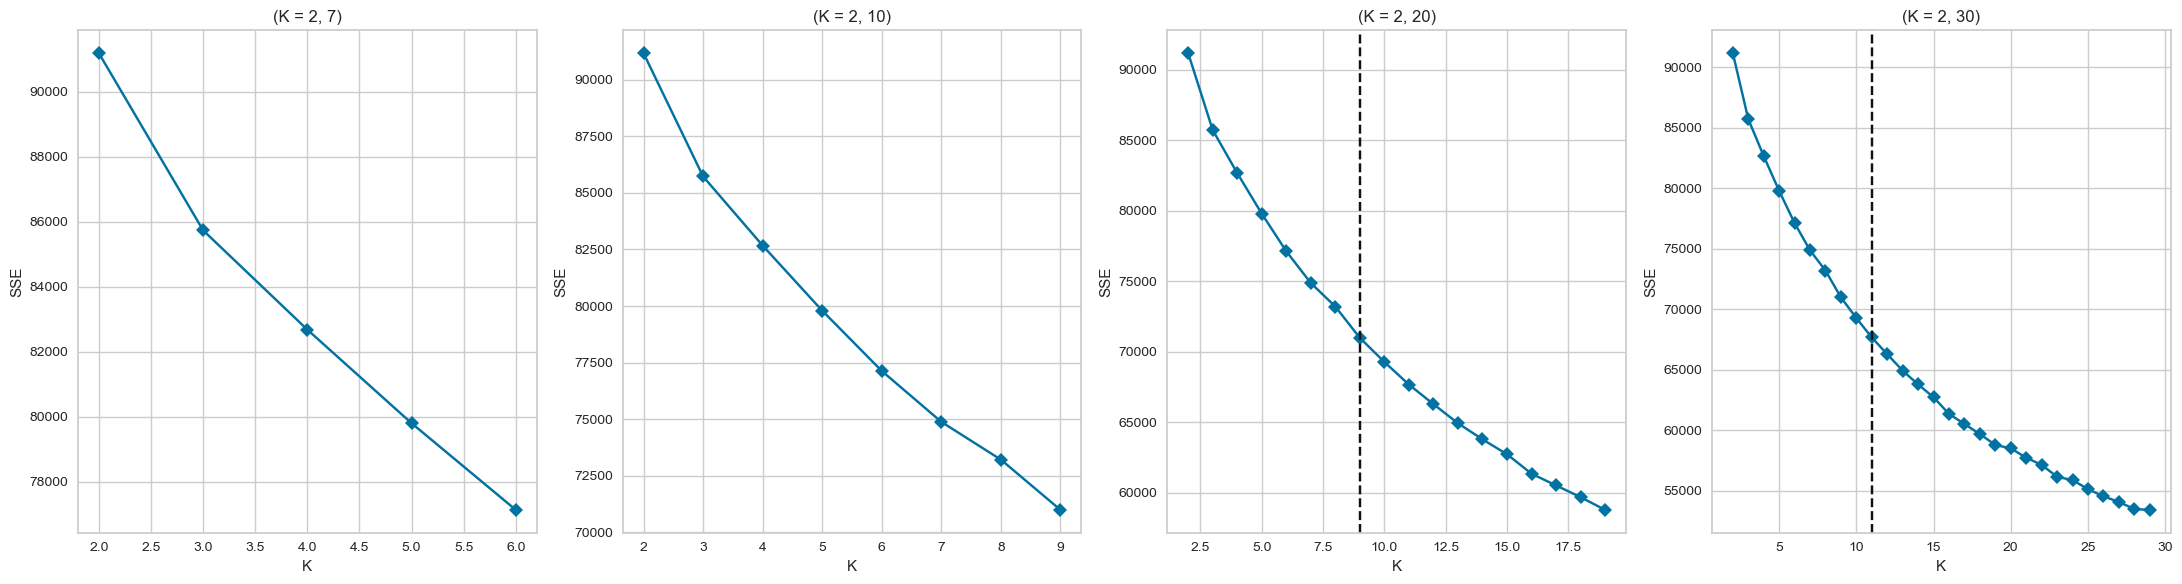

K suggested by the elbow method: [np.int64(9), np.int64(11)]


In [5]:
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

random_state = 42  # fixed seed
# Multiple ranges to test (2->7, 2->10, 2->20, 2->30)
k_start = 2
k_max_list = [7,10, 20, 30]

model = KMeans(n_init=10, max_iter=500, random_state=random_state)

fig, axs = plt.subplots(1, len(k_max_list), figsize=(22, 6))

best_Ks = []

for i, k_max in enumerate(k_max_list):
    
    visualizer = KElbowVisualizer(
        model,
        k=(k_start, k_max),
        metric='distortion',    # SSE (inertia)
        timings=False,
        ax=axs[i]
    )

    visualizer.fit(X)  
    
    axs[i].set_title(f'(K = {k_start}, {k_max})')
    axs[i].set_ylabel('SSE')
    axs[i].set_xlabel('K')
    
    elbow_k = visualizer.elbow_value_
    elbow_score = visualizer.elbow_score_

    if elbow_k is not None and elbow_k not in best_Ks:
        best_Ks.append(elbow_k)

plt.tight_layout()
plt.show()
plt.style.use("default") 


print("K suggested by the elbow method:", best_Ks)


In [6]:
# Metric evaluation loop for k from 2 to 11
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn import metrics

results = []

# Evaluate k from 2 to 11
for k in range(2, 12):
    kmeans = KMeans(n_clusters=k, n_init=10, max_iter=500, random_state=random_state)
    kmeans.fit(X)
    labels = kmeans.labels_
    
    sse = kmeans.inertia_
    silhouette = silhouette_score(X, labels)
    db = metrics.davies_bouldin_score(X, labels)
    
    results.append([k, sse, silhouette, db])

results_df = pd.DataFrame(results, columns=["K", "SSE", "Silhouette", "DB_score"])
print(results_df)


    K           SSE  Silhouette  DB_score
0   2  91180.678978    0.276952  2.286075
1   3  85729.257041    0.103684  2.648733
2   4  82673.519176    0.061431  2.859965
3   5  79794.271025    0.054757  2.699014
4   6  77127.603206    0.056370  2.567807
5   7  74877.149679    0.063603  2.485356
6   8  73205.341646    0.062713  2.476243
7   9  70984.652528    0.066455  2.309463
8  10  69276.359924    0.061387  2.237819
9  11  67672.755551    0.070461  2.102006


Looking at the metrics, k = 2 is the most convincing choice: the silhouette score is clearly higher (≈0.28) than for all other values of k, which drop to around 0.06–0.10. This suggests that the data do not appear to form many well-separated groups, but rather a continuum: beyond k = 2, patients are further “split” without creating truly distinct clusters.

/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_59057/2797230565.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=unique_values, y=value_counts, palette="tab10")


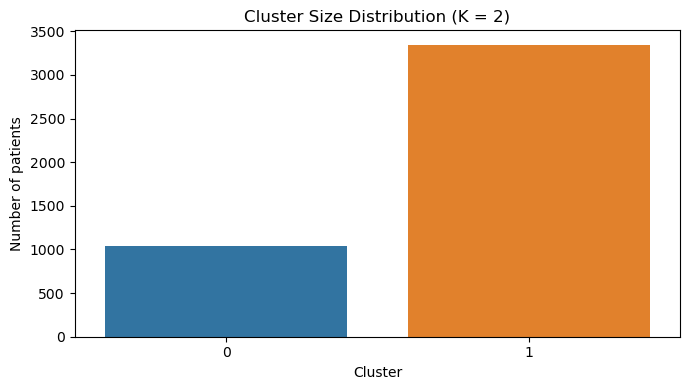

Cluster 0: 1040 patients
Cluster 1: 3344 patients


In [7]:
from sklearn.cluster import KMeans

k = 2
kmeans = KMeans(n_clusters=k, n_init=10, max_iter=500, random_state=random_state)
kmeans.fit(X)

labels = kmeans.labels_

np.unique(labels, return_counts=True)

# Distribution of patients across clusters
unique_values, value_counts = np.unique(labels, return_counts=True)

plt.figure(figsize=(7, 4))
sns.barplot(x=unique_values, y=value_counts, palette="tab10")

plt.xlabel("Cluster")
plt.ylabel("Number of patients")
plt.title("Cluster Size Distribution (K = 2)")
plt.tight_layout()
plt.show()

# Print cluster counts
for c, n in zip(unique_values, value_counts):
    print(f"Cluster {c}: {n} patients")



In [8]:
# Centroids
centroids_scaled = pd.DataFrame(kmeans.cluster_centers_, columns=numeric_df.columns)
centroids_scaled.index.name = "cluster"
display(centroids_scaled)

,number_of_hadm,age,lab_event_count,microbio_test_count,unique_microorganisms_count,unique_procedures_count,max_glucose,max_potassium,max_sodium,max_creatinine,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),min_ph,max_pco2,abnormal_lab_event_ratio
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.542708,0.143400,1.079496,0.926252,0.659451,0.507916,0.853277,0.913826,0.354180,0.833796,...,0.338122,0.592013,0.623348,-0.300429,0.425922,0.578326,-0.070028,-0.453637,0.807807,0.892702
1,-0.168785,-0.044598,-0.335728,-0.288069,-0.205092,-0.157964,-0.265373,-0.284204,-0.110152,-0.259315,...,-0.105158,-0.184119,-0.193864,0.093435,-0.132464,-0.179862,0.021779,0.141083,-0.251232,-0.277635


These numbers are z-scores: 0 is the dataset mean, positive values indicate above average, and negative values indicate below average.

Cluster 0 shows a clearly more “intense/complex” profile: more hospital admissions (number_of_hadm), many more laboratory and microbiology tests (lab_event_count, microbio_test_count), more procedures, and higher maximum values across several markers (e.g. max_glucose, max_creatinine, max_pco2). A markedly above-average abnormal_lab_event_ratio also stands out, indicating a higher proportion of abnormal results. By contrast, max_hemoglobin is below average.

Cluster 1 is the opposite: counts and maxima are generally below average, along with a lower abnormal_lab_event_ratio, indicating a more “standard/stable” profile compared to Cluster 0.

In [9]:
# Attach labels to original profile dataframe
assert len(labels) == len(profile_df) == len(numeric_df)

dfc = profile_df.copy()
dfc["cluster"] = labels

In [10]:
# Means and medians of clusters
means = dfc.groupby("cluster")[numeric_df.columns].mean()
medians = dfc.groupby("cluster")[numeric_df.columns].median()
print("Cluster Means:")
display(means)
print("Cluster Medians:")
display(medians)


Cluster Means:


,number_of_hadm,age,lab_event_count,microbio_test_count,unique_microorganisms_count,unique_procedures_count,max_glucose,max_potassium,max_sodium,max_creatinine,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),min_ph,max_pco2,abnormal_lab_event_ratio
cluster,,,,,,,,,,,,,,,,,,,,,
0,1.310577,71.448077,338.670192,2.718269,0.594231,4.842308,5.521763,1.069194,0.745272,3.720055,...,7.943400,5.191349,7.313942,-0.305396,0.544359,1.559723,0.175934,-0.236154,1.060385,0.504031
1,1.043959,69.674043,90.342105,0.739833,0.079545,2.689892,2.380518,0.620047,0.604042,1.163577,...,1.125897,2.414856,2.474806,-0.117875,0.331688,0.760390,0.219387,0.046531,0.114085,0.325860


Cluster Medians:


,number_of_hadm,age,lab_event_count,microbio_test_count,unique_microorganisms_count,unique_procedures_count,max_glucose,max_potassium,max_sodium,max_creatinine,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),min_ph,max_pco2,abnormal_lab_event_ratio
cluster,,,,,,,,,,,,,,,,,,,,,
0,1.0,71.0,272.0,2.0,0.0,4.0,4.433333,1.000000,0.750000,2.428571,...,0.0,4.539130,3.5,-0.31345,0.455586,1.285714,0.0,0.0,0.6,0.500000
1,1.0,69.0,74.0,0.0,0.0,2.0,1.866667,0.611111,0.666667,0.857143,...,0.0,0.853846,1.0,-0.05000,0.280000,0.657143,0.0,0.0,0.0,0.333333


On the real scale, the difference between the clusters is very clear and seems to primarily describe an axis of clinical intensity/complexity.

Cluster 0 (more intense): many more laboratory tests, more procedures, and more microbiological activity. The abnormal_lab_event_ratio is also higher, consistent with a more “altered” clinical profile. On average, higher maximum values are also observed (e.g. glucose and creatinine).

Cluster 1 (more standard): the opposite profile, with much lower counts and a more contained abnormality ratio. The zero medians for microbiology indicate that many patients in this group have no recorded microbiological tests.

Age and number of hospital admissions change little (similar medians), so the separation is not “demographic” but is mainly related to how much and how often patients are tested/undergo procedures and how many abnormalities emerge.

In [11]:
# Top features that distinguish each cluster
z = centroids_scaled.copy()

for c in z.index:
    top_pos = z.loc[c].sort_values(ascending=False).head(8)
    top_neg = z.loc[c].sort_values(ascending=True).head(8)
    print(f"\n=== Cluster {c} (n={np.sum(labels==c)}) ===")
    print("==Above average:==")
    print(top_pos)
    print("==Below average:==")
    print(top_neg)



=== Cluster 0 (n=1040) ===
==Above average:==
lab_event_count             1.079496
max_urea nitrogen           1.067761
microbio_test_count         0.926252
max_potassium               0.913826
abnormal_lab_event_ratio    0.892702
max_glucose                 0.853277
max_creatinine              0.833796
max_pco2                    0.807807
Name: 0, dtype: float64
==Below average:==
min_ph                              -0.453637
max_hemoglobin                      -0.300429
max_cholesterol ratio (total/hdl)   -0.070028
age                                  0.143400
max_troponin t                       0.319937
max_ntprobnp                         0.338122
max_sodium                           0.354180
max_calcium, total                   0.397125
Name: 0, dtype: float64

=== Cluster 1 (n=3344) ===
==Above average:==
min_ph                               0.141083
max_hemoglobin                       0.093435
max_cholesterol ratio (total/hdl)    0.021779
age                                 -

In [12]:
# Spread across clusters to identify the most discriminative features
# The features with the largest spread are where clusters are most separated (at centroid level).
spread = centroids_scaled.max(axis=0) - centroids_scaled.min(axis=0)
display(spread.sort_values(ascending=False).head(15))


lab_event_count                1.415225
max_urea nitrogen              1.399840
microbio_test_count            1.214321
max_potassium                  1.198030
abnormal_lab_event_ratio       1.170337
max_glucose                    1.118651
max_creatinine                 1.093110
max_pco2                       1.059039
unique_microorganisms_count    0.864543
max_inr(pt)                    0.817212
max_bicarbonate                0.785675
max_ptt                        0.776132
max_white blood cells          0.758188
number_of_hadm                 0.711493
unique_procedures_count        0.665881
dtype: float64

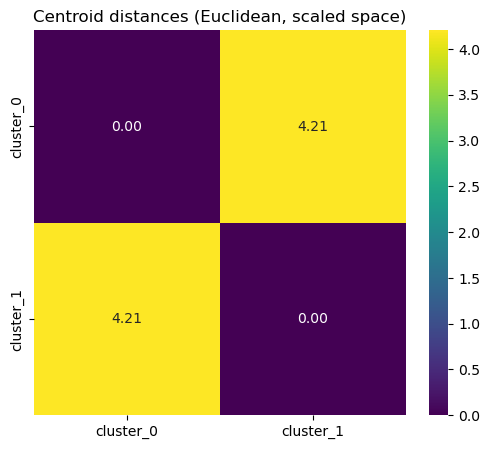

In [13]:
# Centroids in the standardized space (z-score) where KMeans was fit
centers = pd.DataFrame(
    kmeans.cluster_centers_,
    index=[f"cluster_{i}" for i in range(kmeans.n_clusters)],
    columns=numeric_df.columns
)

C = centers.to_numpy()
dist_matrix = np.linalg.norm(C[:, None, :] - C[None, :, :], axis=2)


plt.figure(figsize=(6, 5))
sns.heatmap(
    dist_matrix,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    xticklabels=centers.index,
    yticklabels=centers.index
)
plt.title("Centroid distances (Euclidean, scaled space)")
plt.show()

# Interpretation:
# - Each cell (i, j) shows how far apart centroids i and j are in standardized space.
# - Larger values: clusters are more separated (centroids farther apart).
# - Smaller values: clusters are more similar on average (centroids closer).



Manual pairs used: [('age', 'lab_event_count'), ('age', 'microbio_test_count'), ('lab_event_count', 'unique_procedures_count'), ('max_glucose', 'abnormal_lab_event_ratio')]


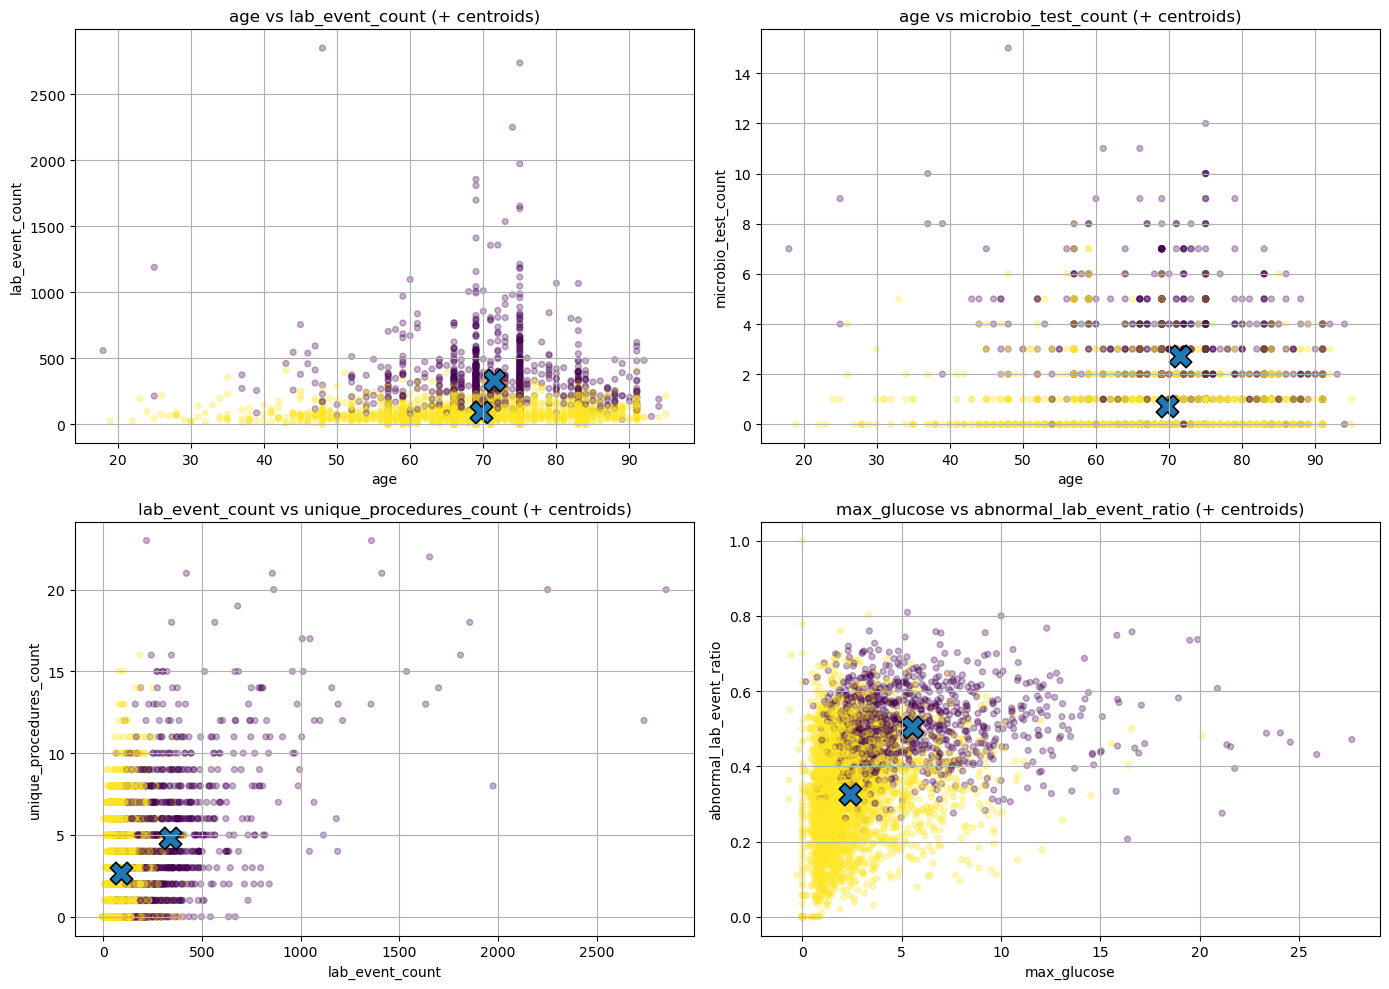

Extra pairs used: [('max_creatinine', 'max_urea nitrogen'), ('max_creatinine', 'max_potassium'), ('max_inr(pt)', 'max_ptt'), ('max_inr(pt)', 'max_platelet count')]


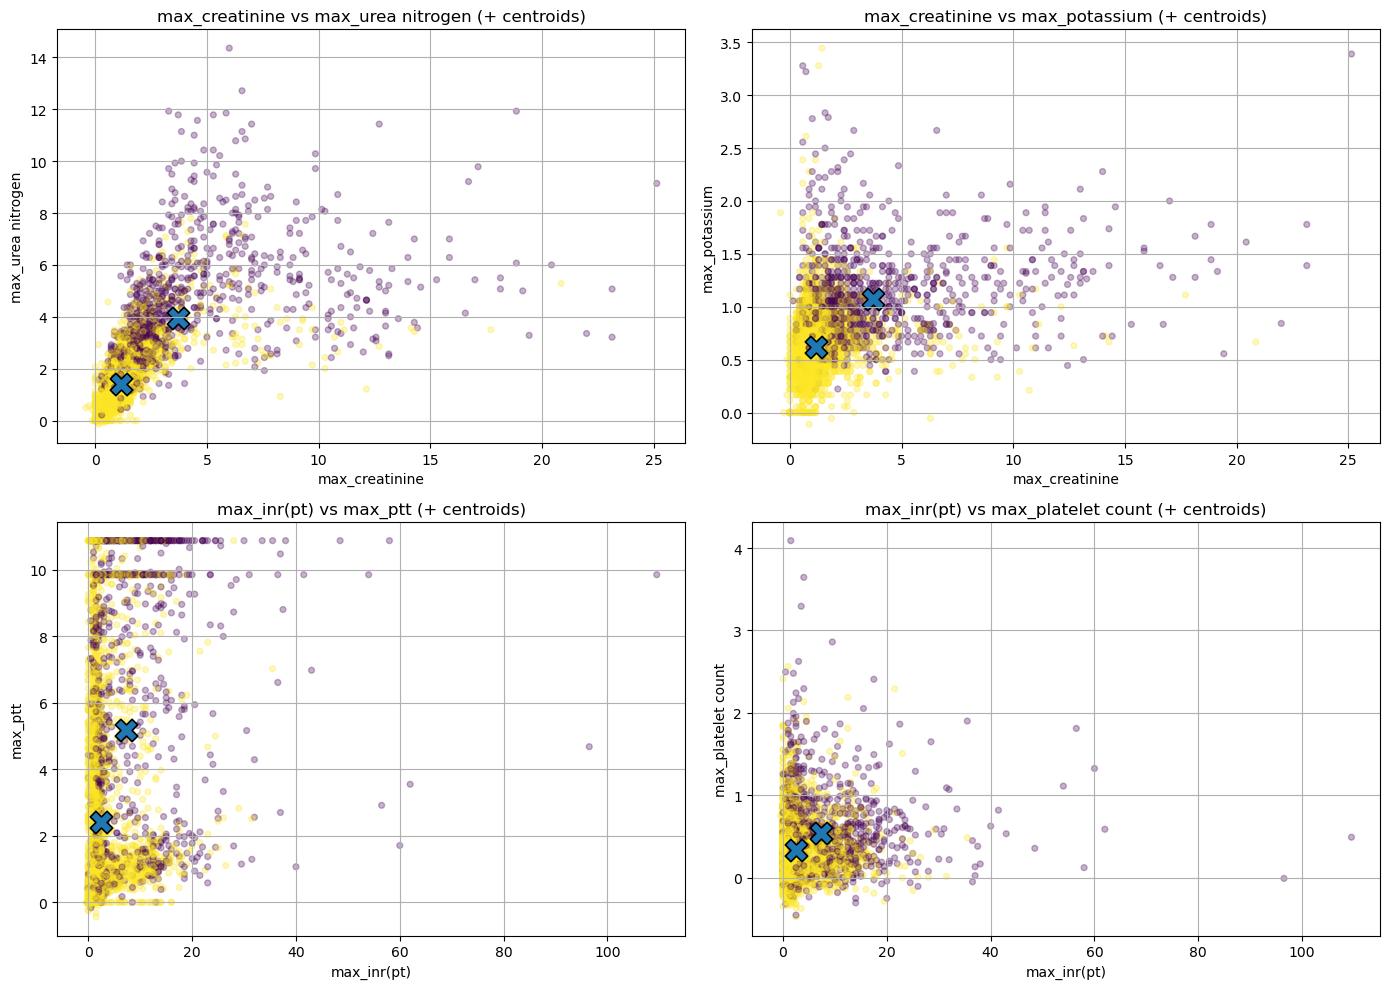

In [14]:
import numpy as np
import matplotlib.pyplot as plt

def scatter_with_centroids(ax, xcol, ycol, df, labels, kmeans, scaler, numeric_cols,
                           s=20, alpha=0.35, centroid_size=260):
    """
    Scatter plot in the original scale (df) colored by labels (KMeans on scaled X),
    with centroids back-transformed using the scaler.
    Note: numeric_cols is kept only for compatibility; indexing now relies on df.columns
    (the same order used to build X).
    """

    # Feature indices in the order actually used to build X
    xi = df.columns.get_loc(xcol)
    yi = df.columns.get_loc(ycol)

    x = df[xcol].values
    y = df[ycol].values

    # Centroids in scaled (z-score) space -> back-transformed to original scale
    cent = kmeans.cluster_centers_
    cx = cent[:, xi] * scaler.scale_[xi] + scaler.mean_[xi]
    cy = cent[:, yi] * scaler.scale_[yi] + scaler.mean_[yi]

    sc = ax.scatter(x, y, c=labels, s=s, alpha=alpha)
    ax.scatter(cx, cy, marker="X", s=centroid_size, edgecolor="black", linewidth=1.2)

    ax.set_xlabel(xcol)
    ax.set_ylabel(ycol)
    ax.grid(True)
    return sc

pairs = [
    ("age", "lab_event_count"),
    ("age", "microbio_test_count"),
    ("lab_event_count", "unique_procedures_count"),
    ("max_glucose", "abnormal_lab_event_ratio"),
]

pairs = [(a, b) for a, b in pairs if a in numeric_df.columns and b in numeric_df.columns]
print("Manual pairs used:", pairs)

n = len(pairs)
cols = 2
rows = int(np.ceil(n / cols))

fig, axs = plt.subplots(rows, cols, figsize=(14, 5 * rows))
axs = np.array(axs).reshape(-1)

for idx, (xcol, ycol) in enumerate(pairs):
    scatter_with_centroids(
        axs[idx], xcol, ycol,
        df=numeric_df, labels=labels,
        kmeans=kmeans, scaler=scaler, numeric_cols=numeric_cols,
        s=18, alpha=0.30, centroid_size=260
    )
    axs[idx].set_title(f"{xcol} vs {ycol} (+ centroids)")

for j in range(idx + 1, len(axs)):
    axs[j].axis("off")

plt.tight_layout()
plt.show()

pairs_extra = [
    ("max_creatinine", "max_urea nitrogen"),
    ("max_creatinine", "max_potassium"),
    ("max_inr(pt)", "max_ptt"),
    ("max_inr(pt)", "max_platelet count"),
]

pairs_extra = [(a, b) for a, b in pairs_extra if a in numeric_df.columns and b in numeric_df.columns]
print("Extra pairs used:", pairs_extra)

n = len(pairs_extra)
cols = 2
rows = int(np.ceil(n / cols))

fig, axs = plt.subplots(rows, cols, figsize=(14, 5 * rows))
axs = np.array(axs).reshape(-1)

for idx, (xcol, ycol) in enumerate(pairs_extra):
    scatter_with_centroids(
        axs[idx], xcol, ycol,
        df=numeric_df, labels=labels,
        kmeans=kmeans, scaler=scaler, numeric_cols=numeric_cols,
        s=18, alpha=0.30, centroid_size=260
    )
    axs[idx].set_title(f"{xcol} vs {ycol} (+ centroids)")

for j in range(idx + 1, len(axs)):
    axs[j].axis("off")

plt.tight_layout()
plt.show()


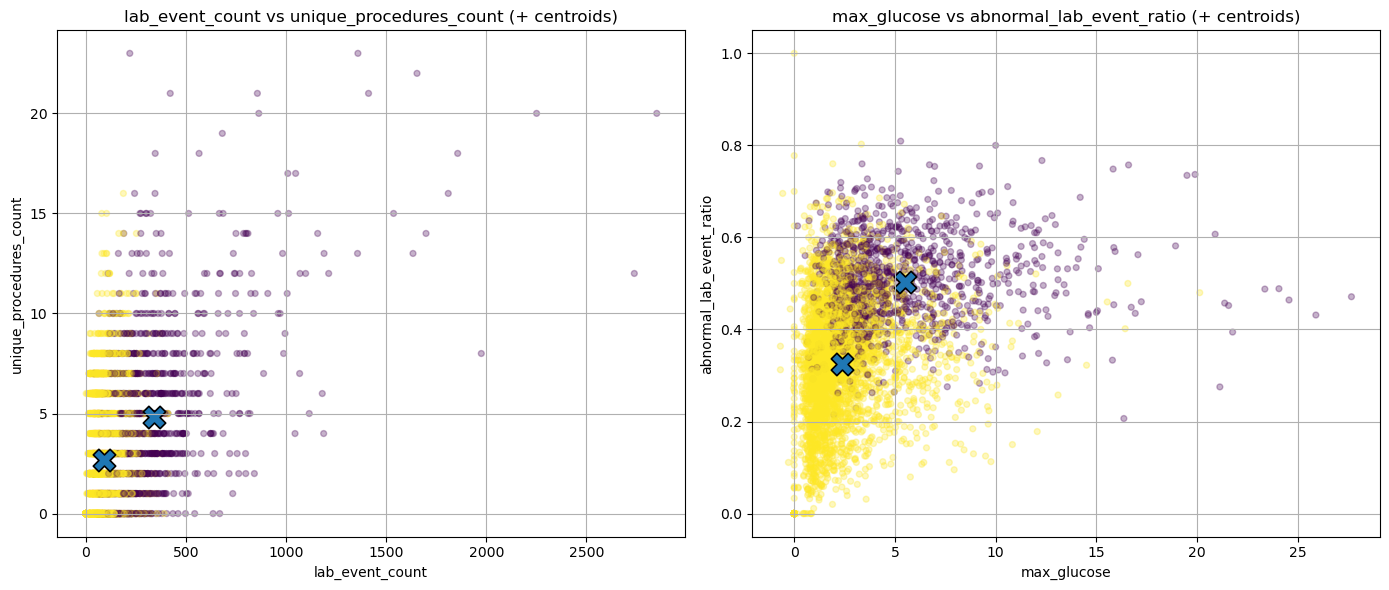

In [15]:
# Scatter plot with centroids for lab_event_count vs unique_procedures_count and max_glucose vs abnormal_lab_event_ratio 
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
scatter_with_centroids(
    axs[0], "lab_event_count", "unique_procedures_count",
    df=numeric_df, labels=labels,
    kmeans=kmeans, scaler=scaler, numeric_cols=numeric_cols,
    s=18, alpha=0.30, centroid_size=260
)
scatter_with_centroids(
    axs[1], "max_glucose", "abnormal_lab_event_ratio",
    df=numeric_df, labels=labels,
    kmeans=kmeans, scaler=scaler, numeric_cols=numeric_cols,
    s=18, alpha=0.30, centroid_size=260
)   
axs[0].set_title("lab_event_count vs unique_procedures_count (+ centroids)")
axs[1].set_title("max_glucose vs abnormal_lab_event_ratio (+ centroids)")   
plt.tight_layout()
plt.show()


Manual triples used: [('age', 'lab_event_count', 'microbio_test_count'), ('lab_event_count', 'unique_procedures_count', 'abnormal_lab_event_ratio'), ('max_glucose', 'abnormal_lab_event_ratio', 'lab_event_count')]


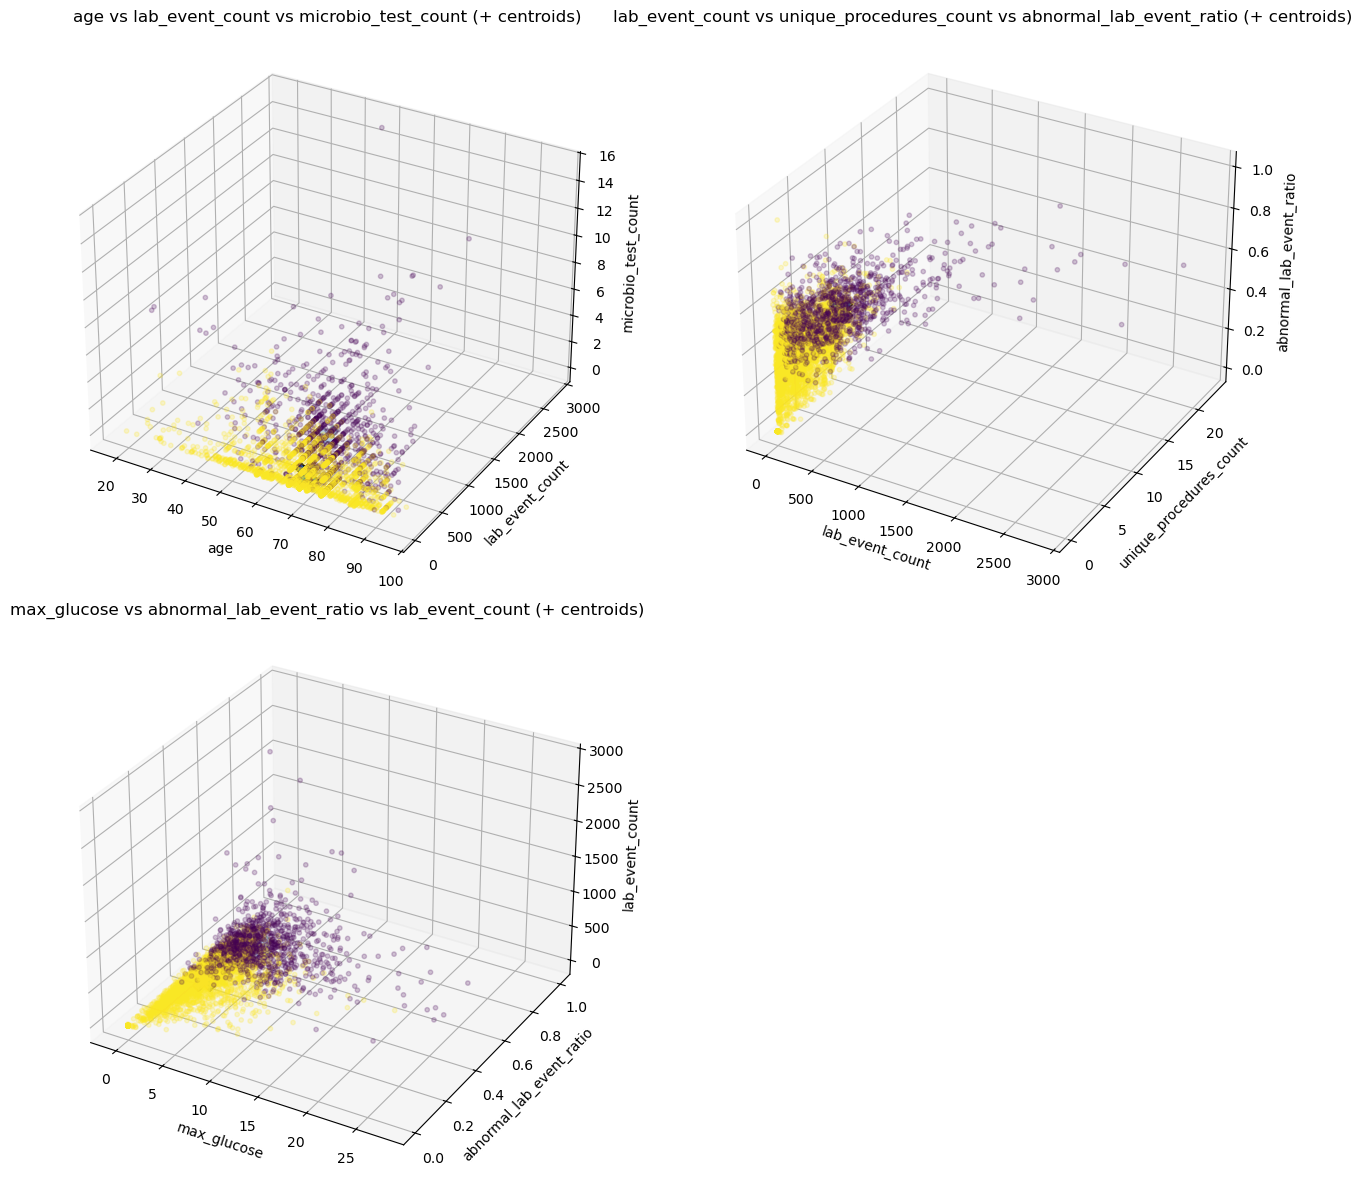

Extra triples used: [('max_creatinine', 'max_urea nitrogen', 'max_potassium'), ('max_inr(pt)', 'max_ptt', 'max_platelet count'), ('max_creatinine', 'max_potassium', 'abnormal_lab_event_ratio')]


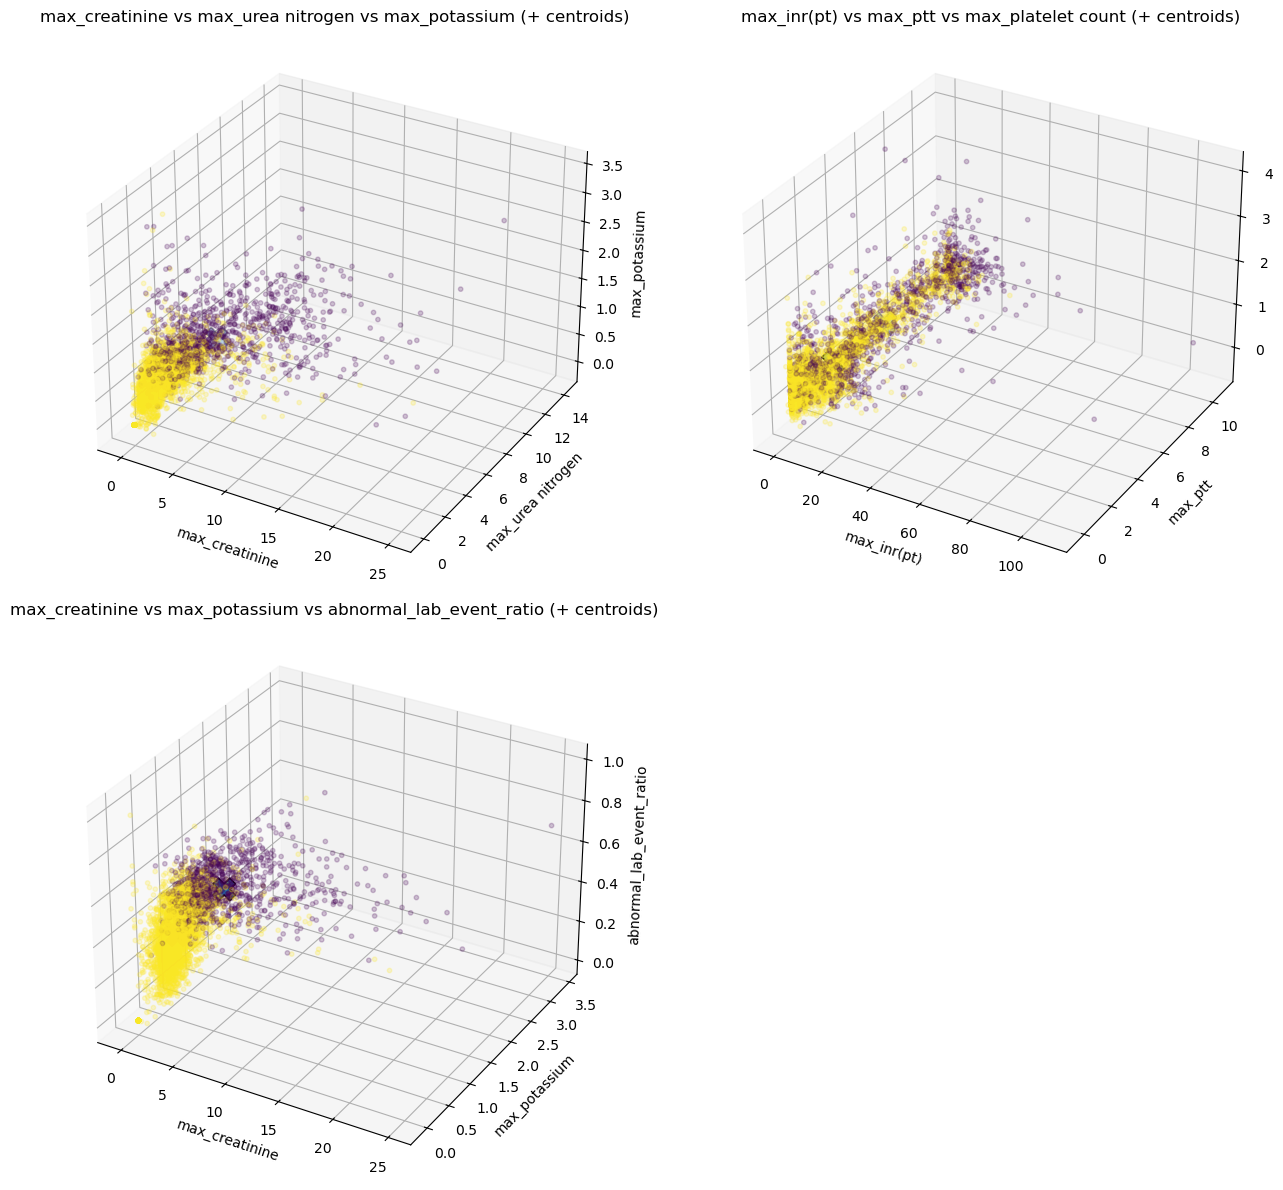

In [16]:

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D 

def scatter3d_with_centroids(ax, xcol, ycol, zcol, df, labels, kmeans, scaler,
                             s=12, alpha=0.25, centroid_size=260):
    """
    3D scatter in the original scale (df) colored by labels (KMeans on scaled X),
    with centroids back-transformed via the scaler.
    """
    
    xi = df.columns.get_loc(xcol)
    yi = df.columns.get_loc(ycol)
    zi = df.columns.get_loc(zcol)

    x = df[xcol].values
    y = df[ycol].values
    z = df[zcol].values

    cent = kmeans.cluster_centers_
    cx = cent[:, xi] * scaler.scale_[xi] + scaler.mean_[xi]
    cy = cent[:, yi] * scaler.scale_[yi] + scaler.mean_[yi]
    cz = cent[:, zi] * scaler.scale_[zi] + scaler.mean_[zi]

    ax.scatter(x, y, z, c=labels, s=s, alpha=alpha)
    ax.scatter(cx, cy, cz, marker="X", s=centroid_size, edgecolor="black", linewidth=1.2)

    ax.set_xlabel(xcol)
    ax.set_ylabel(ycol)
    ax.set_zlabel(zcol)
    ax.set_title(f"{xcol} vs {ycol} vs {zcol} (+ centroids)")
    ax.grid(True)


triples = [
    ("age", "lab_event_count", "microbio_test_count"),
    ("lab_event_count", "unique_procedures_count", "abnormal_lab_event_ratio"),
    ("max_glucose", "abnormal_lab_event_ratio", "lab_event_count"),
]


triples = [(a, b, c) for a, b, c in triples
           if a in numeric_df.columns and b in numeric_df.columns and c in numeric_df.columns]
print("Manual triples used:", triples)

n = len(triples)
cols = 2
rows = int(np.ceil(n / cols))

fig = plt.figure(figsize=(14, 6 * rows))
for i, (xcol, ycol, zcol) in enumerate(triples, start=1):
    ax = fig.add_subplot(rows, cols, i, projection="3d")
    scatter3d_with_centroids(
        ax, xcol, ycol, zcol,
        df=numeric_df, labels=labels, kmeans=kmeans, scaler=scaler,
        s=10, alpha=0.22, centroid_size=260
    )

for j in range(n + 1, rows * cols + 1):
    ax = fig.add_subplot(rows, cols, j, projection="3d")
    ax.set_axis_off()

plt.tight_layout()
plt.show()

triples_extra = [
    ("max_creatinine", "max_urea nitrogen", "max_potassium"),
    ("max_inr(pt)", "max_ptt", "max_platelet count"),
    ("max_creatinine", "max_potassium", "abnormal_lab_event_ratio"),
]

triples_extra = [(a, b, c) for a, b, c in triples_extra
                 if a in numeric_df.columns and b in numeric_df.columns and c in numeric_df.columns]
print("Extra triples used:", triples_extra)

n = len(triples_extra)
cols = 2
rows = int(np.ceil(n / cols))

fig = plt.figure(figsize=(14, 6 * rows))
for i, (xcol, ycol, zcol) in enumerate(triples_extra, start=1):
    ax = fig.add_subplot(rows, cols, i, projection="3d")
    scatter3d_with_centroids(
        ax, xcol, ycol, zcol,
        df=numeric_df, labels=labels, kmeans=kmeans, scaler=scaler,
        s=10, alpha=0.22, centroid_size=260
    )

for j in range(n + 1, rows * cols + 1):
    ax = fig.add_subplot(rows, cols, j, projection="3d")
    ax.set_axis_off()

plt.tight_layout()
plt.show()


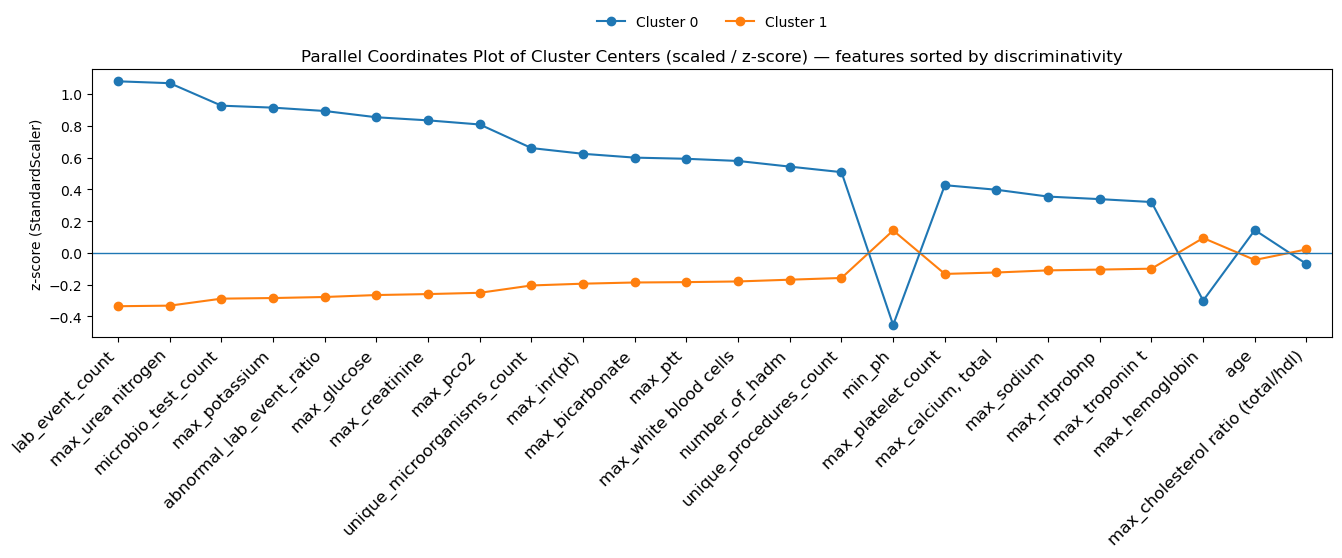

In [17]:
# Parallel Coordinates (centroids in z-score) with features ordered by discriminativity

centers_scaled = kmeans.cluster_centers_  
cols = list(numeric_df.columns)

# Discriminativity = (max - min) across centroids per feature (in z-score)
spread = centers_scaled.max(axis=0) - centers_scaled.min(axis=0)
order = np.argsort(-spread) 

centers_ord = centers_scaled[:, order]
cols_ord = [cols[i] for i in order]

N = centers_ord.shape[1]
x = np.arange(N)

plt.figure(figsize=(16, 4))
for i in range(centers_ord.shape[0]):
    plt.plot(x, centers_ord[i], marker='o', label=f'Cluster {i}')

plt.axhline(0, linewidth=1) 
plt.xticks(x, cols_ord, fontsize=12, rotation=45, ha='right')
plt.xlim(-0.5, N - 0.5)
plt.ylabel("z-score (StandardScaler)")

plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.25),
           ncol=centers_ord.shape[0], frameon=False)

plt.subplots_adjust(top=0.78)
plt.title("Parallel Coordinates Plot of Cluster Centers (scaled / z-score) — features sorted by discriminativity")
plt.show()


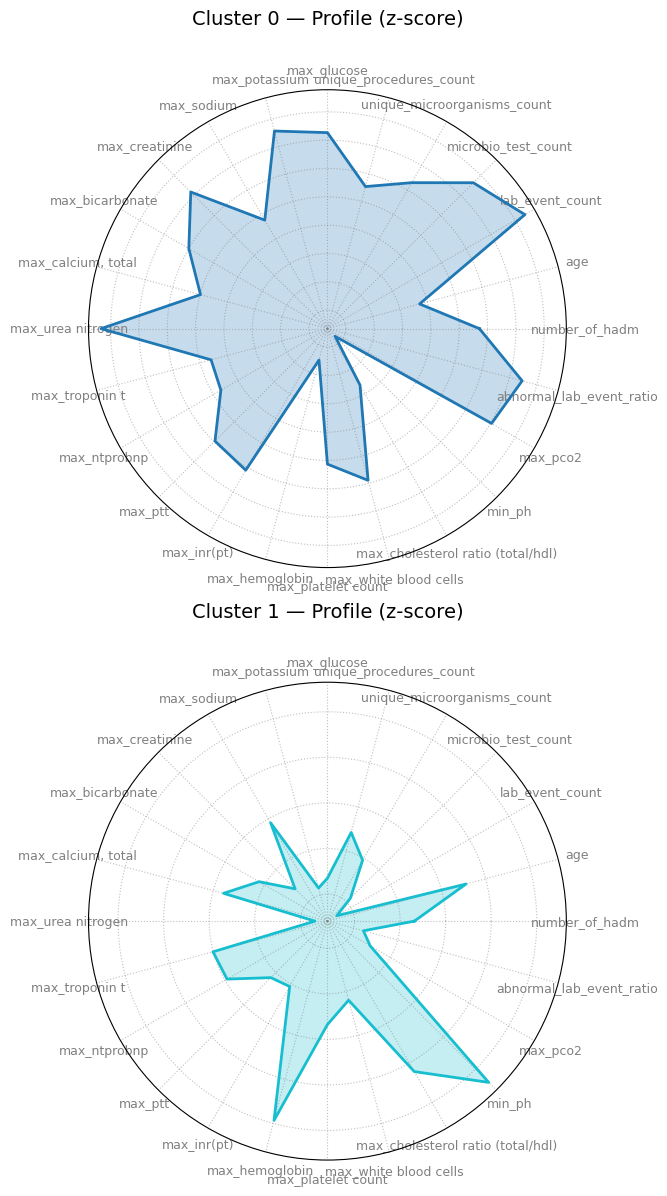

In [18]:
from math import pi
import numpy as np
import matplotlib.pyplot as plt

centers_np = kmeans.cluster_centers_  # scaled (z-score)

N = centers_np.shape[1]
features_labels = numeric_df.columns.tolist()
colors = plt.cm.tab10(np.linspace(0, 1, centers_np.shape[0]))

plt.figure(figsize=(12, 12))

for cluster_id in range(centers_np.shape[0]):
    values = centers_np[cluster_id].tolist()
    values += values[:1]

    angles = [n / float(N) * 2*pi for n in range(N)]
    angles += angles[:1]

    ax = plt.subplot(centers_np.shape[0], 1, cluster_id + 1, polar=True)

    ax.plot(angles, values, linewidth=2, color=colors[cluster_id])
    ax.fill(angles, values, alpha=0.25, color=colors[cluster_id])

    plt.xticks(angles[:-1], features_labels, size=9, color="grey")
    ax.grid(color="grey", linestyle="dotted", alpha=0.5)
    ax.set_yticklabels([])
    ax.set_title(f"Cluster {cluster_id} — Profile (z-score)", size=14, y=1.12)

plt.tight_layout()
plt.show()


/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_59057/3874308676.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")
/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_59057/3874308676.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")
/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_59057/3874308676.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")


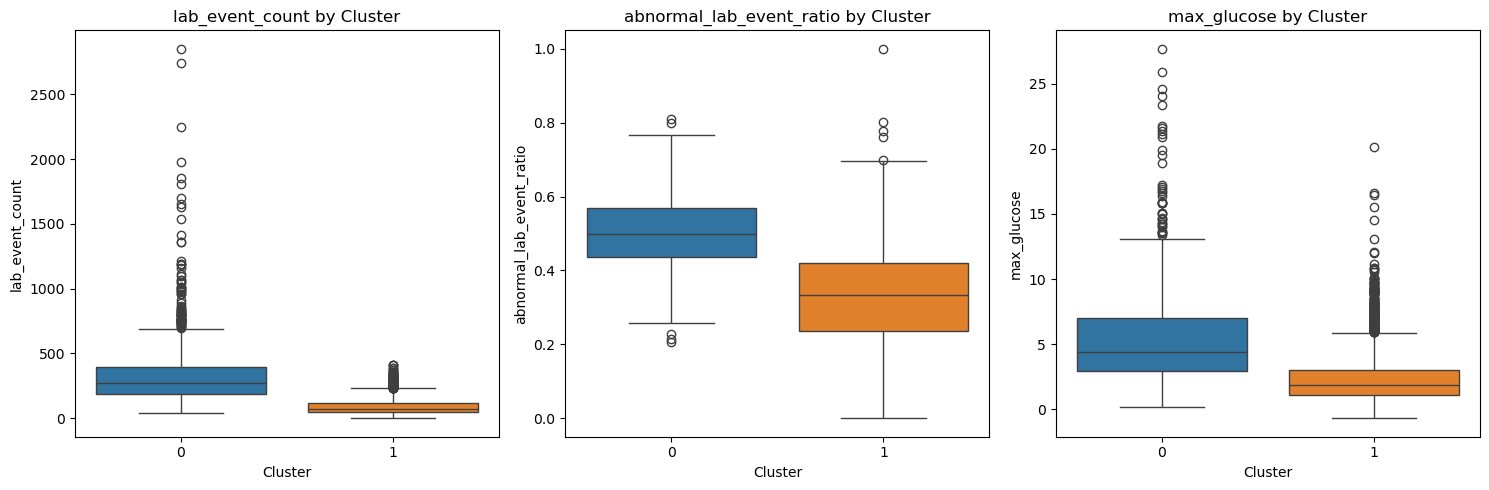

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

df_box = numeric_df.copy()
df_box["Cluster"] = labels

vars_to_plot = [
    "lab_event_count",
    "abnormal_lab_event_ratio",
    "max_glucose",
]

plt.figure(figsize=(15, 5))

for i, var in enumerate(vars_to_plot, 1):
    plt.subplot(1, len(vars_to_plot), i)
    sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")
    plt.title(f"{var} by Cluster")
    plt.xlabel("Cluster")
    plt.ylabel(var)

plt.tight_layout()
plt.show()


The boxplots clearly confirm the separation among the three clusters identified by K-Means. For all three clinical variables considered—lab_event_count, abnormal_lab_event_ratio, and max_glucose—an ordered and coherent structure emerges:

Cluster 0 shows low values across all variables, indicating patients with a simple clinical profile and a very small number of tests performed.

Cluster 1 displays intermediate values, with greater diagnostic activity and a higher level of abnormalities compared to the previous cluster.

Cluster 2 exhibits the highest medians and maxima, standing out as the group of most complex and clinically unstable patients, characterized by a large number of tests, many laboratory abnormalities, and higher glycemic values.

/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_59057/2753307528.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")
/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_59057/2753307528.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")


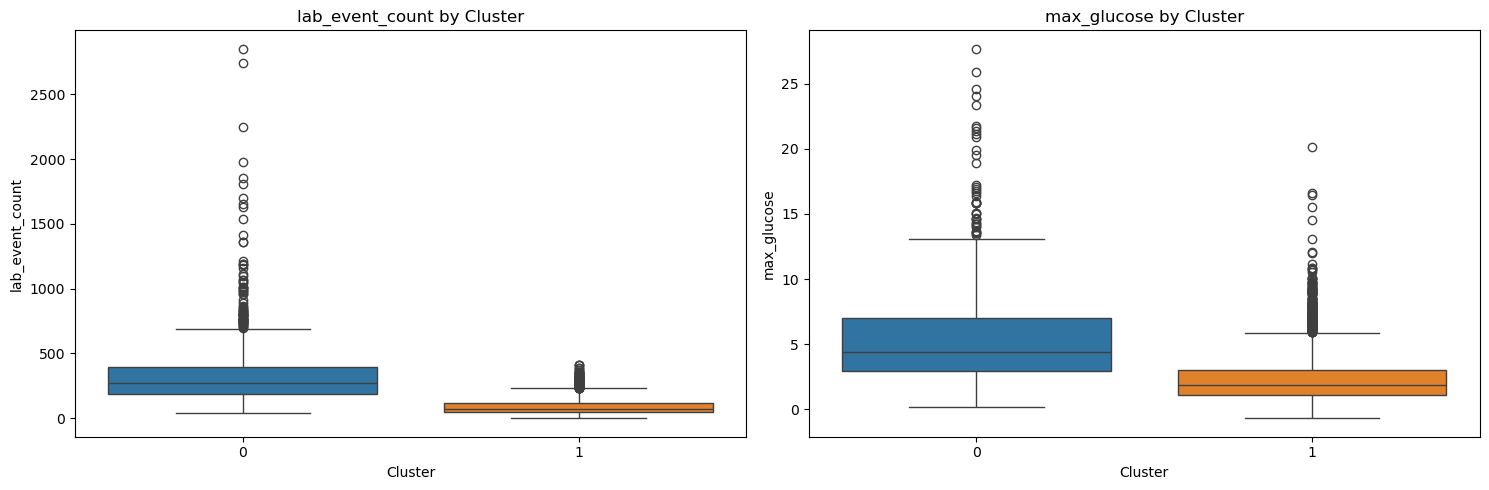

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

df_box = numeric_df.copy()
df_box["Cluster"] = labels

vars_to_plot = [
    "lab_event_count",
    "max_glucose",
]

plt.figure(figsize=(15, 5))

for i, var in enumerate(vars_to_plot, 1):
    plt.subplot(1, len(vars_to_plot), i)
    sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")
    plt.title(f"{var} by Cluster")
    plt.xlabel("Cluster")
    plt.ylabel(var)

plt.tight_layout()
plt.show()


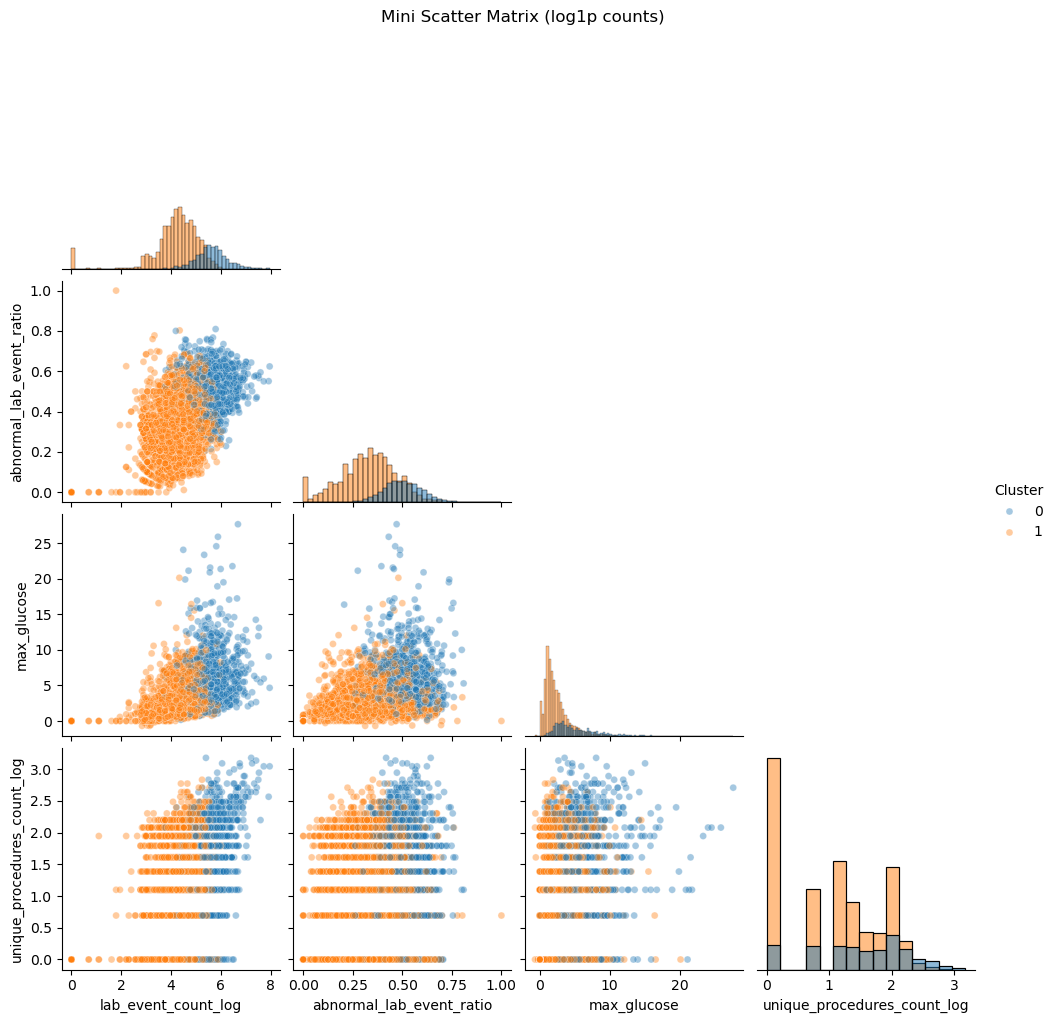

In [21]:
df_scatter = numeric_df.copy()
df_scatter["Cluster"] = labels

df_scatter["lab_event_count_log"] = np.log1p(df_scatter["lab_event_count"])
df_scatter["unique_procedures_count_log"] = np.log1p(df_scatter["unique_procedures_count"])

vars_scatter = [
    "lab_event_count_log",
    "abnormal_lab_event_ratio",
    "max_glucose",
    "unique_procedures_count_log"
]

sns.pairplot(
    df_scatter[vars_scatter + ["Cluster"]],
    hue="Cluster",
    palette="tab10",
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.4, "s": 25}
)

plt.suptitle("Mini Scatter Matrix (log1p counts)", y=1.02)
plt.show()
